In [1]:
# کتابخانه‌های موجود Colab دوباره نصب یا ارتقا داده نمی‌شوند.
import importlib.util
import subprocess
import sys

requirements = {
    "huggingface_hub": "huggingface_hub>=0.34,<2",
    "cv2": "opencv-python-headless<4.12",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn>=0.13",
    "torch": "torch",
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Dependencies ready. Existing PyTorch/CUDA installation preserved.")


Dependencies ready. Existing PyTorch/CUDA installation preserved.


In [2]:
from pathlib import Path
import os
import json
import shutil

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL-Project/image_neural_network")
LOCAL_ROOT = Path("/content/preprocess_work")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)

CACHE_DIR = PROJECT_DIR / "data/video_cache"       # نسخهٔ ماندگار ویدئوها
LOCAL_VIDEO_DIR = LOCAL_ROOT / "video_cache"       # نسخهٔ محلی برای پردازش
LOCAL_NPZ_DIR = LOCAL_ROOT / "npz"                 # فایل موقت فریم‌ها
FRAME_DIR = PROJECT_DIR / "data/preprocessed_300_0p2s_224"
for directory in [CACHE_DIR, LOCAL_VIDEO_DIR, LOCAL_NPZ_DIR, FRAME_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# کش کتابخانهٔ Hugging Face نیز محلی می‌ماند، نه روی Drive.
os.environ["HF_HOME"] = str(LOCAL_ROOT / "huggingface")

print("Project on Drive:", PROJECT_DIR)
print("Original videos on Drive:", CACHE_DIR)
print("Final NPZ output on Drive:", FRAME_DIR)
print("Temporary processing:", LOCAL_ROOT)
print(f"Local disk free: {shutil.disk_usage(LOCAL_ROOT).free / 1024**3:.1f} GiB")
print("Drive storage quota must be checked separately in Google Drive.")


Mounted at /content/drive
Project on Drive: /content/drive/MyDrive/DL-Project/image_neural_network
Original videos on Drive: /content/drive/MyDrive/DL-Project/image_neural_network/data/video_cache
Final NPZ output on Drive: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224
Temporary processing: /content/preprocess_work
Local disk free: 87.1 GiB
Drive storage quota must be checked separately in Google Drive.


In [3]:
from getpass import getpass
from huggingface_hub import HfApi, hf_hub_download, get_token

REPO_ID = "nexar-ai/nexar_collision_prediction"
HF_TOKEN = get_token()
if not HF_TOKEN:
    HF_TOKEN = getpass("Hugging Face READ token (hidden): ").strip()
if not HF_TOKEN:
    raise ValueError("A Hugging Face token with dataset access is required.")

api = HfApi(token=HF_TOKEN)
config_path = PROJECT_DIR / "data/preprocessing_config_300.json"
expected_settings = {
    "repo_id": REPO_ID, "seed": 42,
    "sample_count": 300, "train_count": 240, "val_count": 60,
    "frame_interval": 0.2, "image_size": [224, 224],
    "sampling_scope": "entire_video",
}

if config_path.is_file():
    saved_config = json.loads(config_path.read_text(encoding="utf-8"))
    for key, value in expected_settings.items():
        if saved_config.get(key) != value:
            raise ValueError(f"Existing preprocessing setting differs: {key}. "
                             "Use a separate PROJECT_DIR for a new experiment.")
    DATASET_REVISION = saved_config["dataset_revision"]
    print("Reusing recorded dataset revision:", DATASET_REVISION)
else:
    # A previous 350-video run may already have recorded the dataset revision.
    # Keep that source version while saving the new counts separately.
    previous_config_path = PROJECT_DIR / "data/preprocessing_config.json"
    previous_config = (
        json.loads(previous_config_path.read_text(encoding="utf-8"))
        if previous_config_path.is_file() else {}
    )
    if previous_config.get("repo_id") == REPO_ID and previous_config.get("dataset_revision"):
        DATASET_REVISION = previous_config["dataset_revision"]
    else:
        DATASET_REVISION = api.dataset_info(repo_id=REPO_ID).sha
    if not DATASET_REVISION:
        raise RuntimeError("Could not resolve dataset revision.")
    saved_config = {**expected_settings, "dataset_revision": DATASET_REVISION}
    config_path.parent.mkdir(parents=True, exist_ok=True)
    temporary_config = config_path.with_suffix(".tmp.json")
    temporary_config.write_text(json.dumps(saved_config, indent=2), encoding="utf-8")
    temporary_config.replace(config_path)
    print("Recorded dataset revision:", DATASET_REVISION)


def publish_file(source, destination):
    """Copy a completed local file; publish its final name after the copy."""
    source, destination = Path(source), Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".uploading")
    try:
        shutil.copyfile(source, temporary)
        if temporary.stat().st_size != source.stat().st_size:
            raise IOError(f"Incomplete copy: {destination}")
        temporary.replace(destination)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise


def get_video(video_path):
    """Reuse Drive originals, decode locally, or download only this video."""
    relative = Path(video_path)
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError("Expected a relative dataset video path.")
    local = LOCAL_VIDEO_DIR / relative
    archived = CACHE_DIR / relative

    if local.is_file() and local.stat().st_size > 0:
        if not archived.is_file():
            publish_file(local, archived)
        return local

    if archived.is_file() and archived.stat().st_size > 0:
        publish_file(archived, local)
        return local

    print("Downloading:", video_path, flush=True)
    downloaded = Path(hf_hub_download(
        repo_id=REPO_ID, repo_type="dataset", filename=video_path,
        revision=DATASET_REVISION, token=HF_TOKEN,
        local_dir=str(LOCAL_VIDEO_DIR),
    ))
    publish_file(downloaded, archived)
    return downloaded


print("Dataset access configured. No token is printed or saved on Drive.")


Hugging Face READ token (hidden): ··········
Reusing recorded dataset revision: 7535d0656dac31d7da2846913bb69c6331d2a70a
Dataset access configured. No token is printed or saved on Drive.


بررسی ساختار دیتاست


In [4]:
from huggingface_hub import HfApi
from huggingface_hub.hf_api import RepoFile, RepoFolder
from collections import Counter
from pathlib import PurePosixPath
import pandas as pd

# ==========================================
# 1. Dataset Configuration
# ==========================================

REPO_ID = "nexar-ai/nexar_collision_prediction"

api = HfApi(token=HF_TOKEN)

# ==========================================
# 2. Get Repository Structure
# ==========================================

print("Fetching dataset structure...")

items = list(api.list_repo_tree(
    repo_id=REPO_ID,
    repo_type="dataset",
    recursive=True,
    revision=DATASET_REVISION
))

# Separate files and folders
repo_files = [
    f for f in items
    if isinstance(f, RepoFile)
]

repo_folders = [
    f for f in items
    if isinstance(f, RepoFolder)
]

print("\n========== DATASET INFORMATION ==========")

print("Repository:", REPO_ID)
print("Total files:", len(repo_files))
print("Total folders:", len(repo_folders))

# ==========================================
# 3. Folder Structure
# ==========================================

print("\n========== FOLDER STRUCTURE ==========")

for folder in sorted(repo_folders, key=lambda x: x.path):
    depth = folder.path.count("/")

    if depth <= 2:
        print("  " * depth + folder.path)

# ==========================================
# 4. File Format Distribution
# ==========================================

extensions = Counter(
    PurePosixPath(f.path).suffix.lower()
    for f in repo_files
)

print("\n========== FILE FORMATS ==========")

for ext, count in sorted(extensions.items()):
    print(f"{ext or '[no extension]'}: {count}")

# ==========================================
# 5. Create File Inventory
# ==========================================

inventory = pd.DataFrame([
    {
        "path": f.path,
        "type": "file",
        "extension": PurePosixPath(f.path).suffix.lower(),
        "size_mb": (
            round(f.size / (1024**2), 2)
            if f.size is not None else None
        )
    }
    for f in repo_files
])

print("\n========== FILE INVENTORY ==========")

display(inventory.head(20))

# ==========================================
# 6. Video Distribution
# ==========================================

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}

videos = inventory[
    inventory["extension"].isin(video_extensions)
].copy()

videos["folder"] = videos["path"].apply(
    lambda x: str(PurePosixPath(x).parent)
)

print("\n========== VIDEO DISTRIBUTION ==========")

video_distribution = (
    videos.groupby("folder")
    .size()
    .reset_index(name="video_count")
)

display(video_distribution)

print("Total videos:", len(videos))

# ==========================================
# 7. Dataset Size
# ==========================================

print("\n========== DATASET SIZE ==========")

total_size_gb = inventory["size_mb"].sum() / 1024
video_size_gb = videos["size_mb"].sum() / 1024

print(f"Total dataset size: {total_size_gb:.2f} GB")
print(f"Total video size: {video_size_gb:.2f} GB")

unknown_sizes = inventory["size_mb"].isna().sum()

if unknown_sizes:
    print(f"Warning: {unknown_sizes} files have unknown sizes.")

# ==========================================
# 8. Metadata Files
# ==========================================

print("\n========== METADATA FILES ==========")

metadata_files = inventory[
    inventory["path"].str.contains(
        r"metadata|\.csv$",
        case=False,
        regex=True
    )
]

display(metadata_files)

# ==========================================
# 9. Sample Video Files
# ==========================================

print("\n========== SAMPLE VIDEOS ==========")

display(
    videos[["path", "size_mb", "folder"]].head(10)
)

# ==========================================
# 10. Summary
# ==========================================

print("\n========== FINAL SUMMARY ==========")

print("Total files:", len(repo_files))
print("Total folders:", len(repo_folders))
print("Total videos:", len(videos))
print("Metadata/CSV files:", len(metadata_files))
print("Dataset size (GB):", round(total_size_gb, 2))

print("\n========== INSPECTION COMPLETED ==========")

Fetching dataset structure...

========== DATASET INFORMATION ==========
Repository: nexar-ai/nexar_collision_prediction
Total files: 2857
Total folders: 9

========== FOLDER STRUCTURE ==========
test-private
  test-private/negative
  test-private/positive
test-public
  test-public/negative
  test-public/positive
train
  train/negative
  train/positive

========== FILE FORMATS ==========
[no extension]: 2
.csv: 9
.md: 1
.mp4: 2844
.py: 1

========== FILE INVENTORY ==========


,path,type,extension,size_mb
0,.gitattributes,file,,0.00
1,LICENSE,file,,0.00
2,README.md,file,.md,0.00
3,evaluate_submission.py,file,.py,0.00
4,sample_submission.csv,file,.csv,0.03
5,solution.csv,file,.csv,0.02
6,test-private/negative/01047.mp4,file,.mp4,2.60
7,test-private/negative/01053.mp4,file,.mp4,4.79
8,test-private/negative/01055.mp4,file,.mp4,5.33
9,test-private/negative/01057.mp4,file,.mp4,5.33



========== VIDEO DISTRIBUTION ==========


,folder,video_count
0,test-private/negative,339
1,test-private/positive,338
2,test-public/negative,333
3,test-public/positive,334
4,train/negative,750
5,train/positive,750


Total videos: 2844

========== DATASET SIZE ==========
Total dataset size: 29.22 GB
Total video size: 29.22 GB

========== METADATA FILES ==========


,path,type,extension,size_mb
4,sample_submission.csv,file,.csv,0.03
5,solution.csv,file,.csv,0.02
345,test-private/negative/metadata.csv,file,.csv,0.01
684,test-private/positive/metadata.csv,file,.csv,0.02
1018,test-public/negative/metadata.csv,file,.csv,0.01
1353,test-public/positive/metadata.csv,file,.csv,0.02
1354,time_to_accident_test_map.csv,file,.csv,0.01
2105,train/negative/metadata.csv,file,.csv,0.02
2856,train/positive/metadata.csv,file,.csv,0.03



========== SAMPLE VIDEOS ==========


,path,size_mb,folder
6,test-private/negative/01047.mp4,2.60,test-private/negative
7,test-private/negative/01053.mp4,4.79,test-private/negative
8,test-private/negative/01055.mp4,5.33,test-private/negative
9,test-private/negative/01057.mp4,5.33,test-private/negative
10,test-private/negative/01063.mp4,5.29,test-private/negative
11,test-private/negative/01064.mp4,3.31,test-private/negative
12,test-private/negative/01077.mp4,2.36,test-private/negative
13,test-private/negative/01082.mp4,3.30,test-private/negative
14,test-private/negative/01086.mp4,2.89,test-private/negative
15,test-private/negative/01087.mp4,2.20,test-private/negative



========== FINAL SUMMARY ==========
Total files: 2857
Total folders: 9
Total videos: 2844
Metadata/CSV files: 9
Dataset size (GB): 29.22

========== INSPECTION COMPLETED ==========


دریافت متادیتا

In [5]:
from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path
import pandas as pd

# 1. Configuration
REPO_ID = "nexar-ai/nexar_collision_prediction"
SAVE_DIR = Path("data/metadata")

SAVE_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi(token=HF_TOKEN)

# 2. Find metadata files
repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset",
    revision=DATASET_REVISION
)

metadata_files = [
    path for path in repo_files
    if Path(path).name.lower() == "metadata.csv"
]

print("Metadata files found:", len(metadata_files))
print(*metadata_files, sep="\n")

# 3. Download and read metadata
metadata_dfs = {}

for file_path in metadata_files:

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=file_path,
        local_dir=SAVE_DIR,
        revision=DATASET_REVISION,
        token=HF_TOKEN
    )

    df = pd.read_csv(local_path)
    metadata_dfs[file_path] = df

    print(f"\n========== {file_path} ==========")

    print("Shape:", df.shape)
    print("\nColumns:", df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nFirst 5 Rows:")
    display(df.head())

print("\nMetadata download completed!")
print("Saved in:", SAVE_DIR.resolve())

Metadata files found: 6
test-private/negative/metadata.csv
test-private/positive/metadata.csv
test-public/negative/metadata.csv
test-public/positive/metadata.csv
train/negative/metadata.csv
train/positive/metadata.csv


metadata.csv:   0%|          | 0.00/13.2k [00:00<?, ?B/s]


========== test-private/negative/metadata.csv ==========
Shape: (339, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name            object
time_of_event       float64
time_of_alert       float64
light_conditions     object
weather              object
scene                object
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event       339
time_of_alert       339
light_conditions      0
weather               0
scene                 0
time_to_accident      0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01047.mp4,NaN,NaN,Normal,Clear,Urban,0.5
1,01053.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
2,01055.mp4,NaN,NaN,Normal,Cloudy,Highway,0.5
3,01057.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
4,01063.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5


metadata.csv:   0%|          | 0.00/17.0k [00:00<?, ?B/s]


========== test-private/positive/metadata.csv ==========
Shape: (338, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name            object
time_of_event       float64
time_of_alert       float64
light_conditions     object
weather              object
scene                object
time_to_accident    float64
dtype: object

Missing Values:
file_name           0
time_of_event       0
time_of_alert       0
light_conditions    0
weather             0
scene               0
time_to_accident    0
dtype: int64

First 5 Rows:


... (8 outputs left out)

,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01924.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN
1,01429.mp4,NaN,NaN,Normal,Rain,Urban,NaN
2,01904.mp4,NaN,NaN,Normal,Cloudy,Urban,NaN
3,01486.mp4,NaN,NaN,Normal,Clear,Urban,NaN
4,01171.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN



========== train/positive/metadata.csv ==========
Shape: (750, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name            object
time_of_event       float64
time_of_alert       float64
light_conditions     object
weather              object
scene                object
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event         0
time_of_alert         0
light_conditions      0
weather               1
scene                 0
time_to_accident    750
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,00822.mp4,19.500,18.633,Normal,Cloudy,Urban,NaN
1,00208.mp4,19.800,19.233,Normal,Cloudy,Sub-urban,NaN
2,00072.mp4,20.101,20.068,Normal,Clear,Urban,NaN
3,00128.mp4,19.267,18.333,Normal,Clear,Urban,NaN
4,00205.mp4,21.146,18.196,Normal,Clear,Highway,NaN



Metadata download completed!
Saved in: /content/drive/MyDrive/DL-Project/image_neural_network/data/metadata


جلوگیری از نشت دیتا ، شماره 1


In [6]:
import pandas as pd

# Columns that may cause Data Leakage
leakage_columns = [
    "time_of_event",
    "time_of_alert",
    "time_to_accident"
]

prepared_metadata = {}

for file_path, original_df in metadata_dfs.items():

    # Keep original data unchanged
    df = original_df.copy()

    # Create binary labels
    df["label"] = df["time_of_event"].notna().astype(int)

    # Remove leakage columns
    df = df.drop(columns=leakage_columns)

    # Store processed metadata
    prepared_metadata[file_path] = df

    print(f"\n{file_path}")
    print("Shape:", df.shape)
    print("Labels:", df["label"].value_counts().to_dict())

# Check final structure
print("\n========== FINAL COLUMNS ==========")
display(prepared_metadata["train/positive/metadata.csv"].head())

# Verify removed columns
for df in prepared_metadata.values():
    assert not any(col in df.columns for col in leakage_columns)

print("\nData Leakage columns removed successfully!- S1")


test-private/negative/metadata.csv
Shape: (339, 5)
Labels: {0: 339}

test-private/positive/metadata.csv
Shape: (338, 5)
Labels: {1: 338}

test-public/negative/metadata.csv
Shape: (333, 5)
Labels: {0: 333}

test-public/positive/metadata.csv
Shape: (334, 5)
Labels: {1: 334}

train/negative/metadata.csv
Shape: (750, 5)
Labels: {0: 750}

train/positive/metadata.csv
Shape: (750, 5)
Labels: {1: 750}

========== FINAL COLUMNS ==========


,file_name,light_conditions,weather,scene,label
0,00822.mp4,Normal,Cloudy,Urban,1
1,00208.mp4,Normal,Cloudy,Sub-urban,1
2,00072.mp4,Normal,Clear,Urban,1
3,00128.mp4,Normal,Clear,Urban,1
4,00205.mp4,Normal,Clear,Highway,1



Data Leakage columns removed successfully!- S1


بررسی کیفیت و سلامت ویدئوها و شناسایی فایل‌های تکراری.

========== METADATA LEAKAGE AUDIT ==========

Probability of Accident (Label=1) given light_conditions:
light_conditions
Bright      0.700000
Normal      0.501845
Dark        0.468085
Twilight    0.465909
Name: label, dtype: float64

Probability of Accident (Label=1) given weather:
weather
Snow      1.000000
Rain      0.722892
Cloudy    0.490909
Clear     0.484222
Name: label, dtype: float64

Probability of Accident (Label=1) given scene:
scene
Nature        1.000000
Other         0.647059
Urban         0.605867
Highway       0.451187
Sub-urban     0.276753
Industrial    0.230769
Rural         0.166667
Name: label, dtype: float64


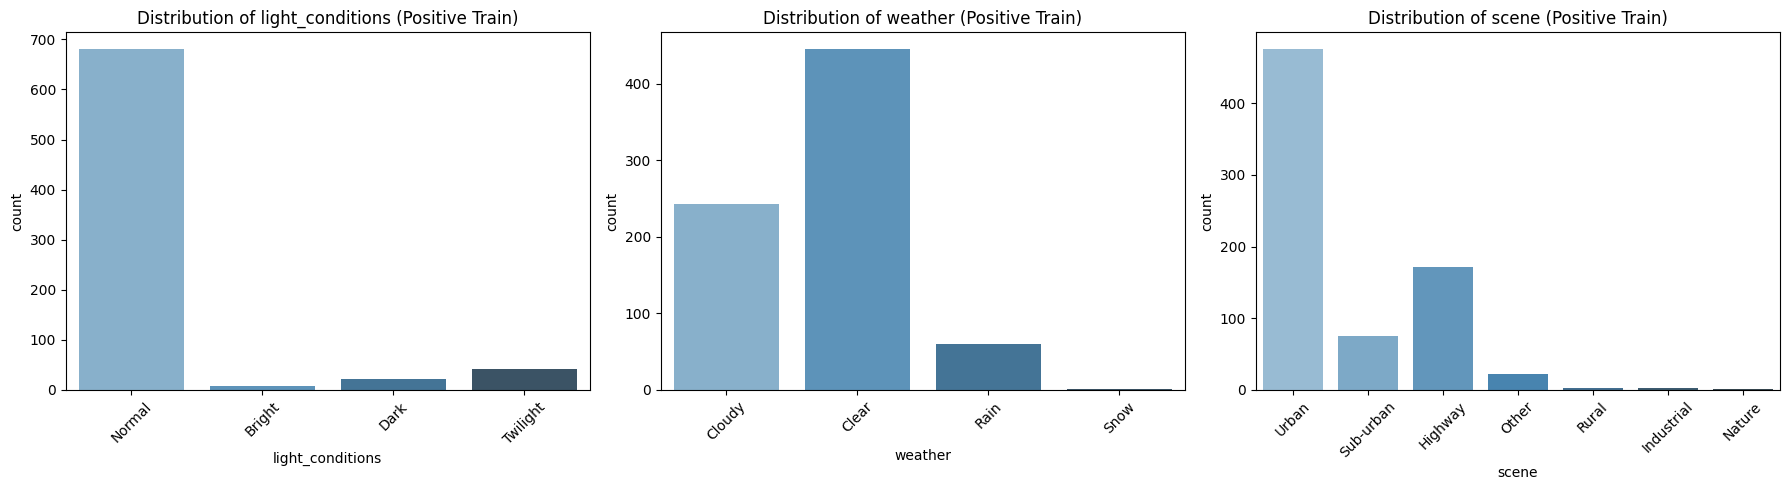

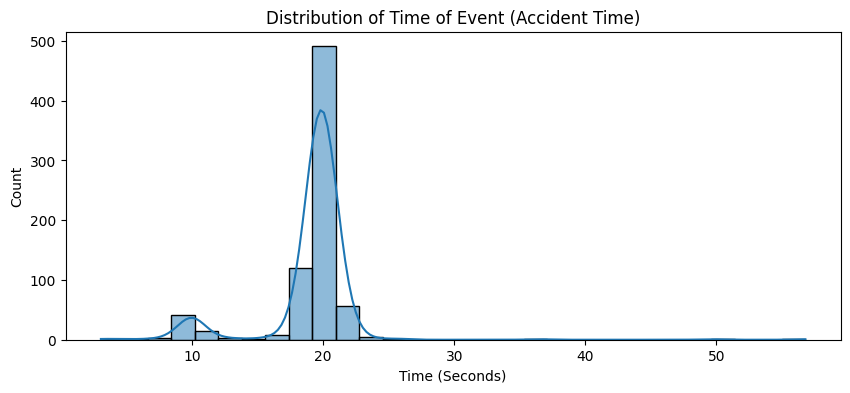

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine positive and negative for leakage audit
df_pos = prepared_metadata['train/positive/metadata.csv']
df_neg = prepared_metadata['train/negative/metadata.csv']
df_all_train = pd.concat([df_pos, df_neg])

# --- 1. METADATA LEAKAGE AUDIT ---
print("========== METADATA LEAKAGE AUDIT ==========")
for col in ['light_conditions', 'weather', 'scene']:
    leakage_check = df_all_train.groupby(col)['label'].mean().sort_values(ascending=False)
    print(f"\nProbability of Accident (Label=1) given {col}:")
    print(leakage_check)

# --- 2. DISTRIBUTION PLOTS (Fixed Warnings) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    sns.countplot(data=df_pos, x=col, ax=axes[i], hue=col, palette="Blues_d", legend=False)
    axes[i].set_title(f'Distribution of {col} (Positive Train)')
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# --- 3. TIME OF EVENT PLOT ---
plt.figure(figsize=(10, 4))
sns.histplot(data=metadata_dfs['train/positive/metadata.csv'], x='time_of_event', bins=30, kde=True)
plt.title('Distribution of Time of Event (Accident Time)')
plt.xlabel('Time (Seconds)')
plt.show()

نمونه‌گیری

In [8]:

import numpy as np
import pandas as pd
from pathlib import Path

# ==========================================
# 1. Configuration
# ==========================================

SEED = 42

DATA_DIR = Path("data/metadata")
OUTPUT_DIR = Path("data/processed_v2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ENV_COLS = ["light_conditions", "weather", "scene"]

# These columns are preserved in metadata,
# but must NOT be used as model inputs.
EXCLUDED_MODEL_COLS = [
    "time_of_event",
    "time_of_alert",
    "time_to_accident",
    "light_conditions",
    "weather",
    "scene",
    "file_name",
    "video_path",
    "label"
]

# ==========================================
# 2. Load Original Training Metadata
# ==========================================

def load_class(class_name, expected_label):

    path = DATA_DIR / "train" / class_name / "metadata.csv"

    df = pd.read_csv(path, dtype={"file_name": str})

    # Create binary labels
    df["label"] = df["time_of_event"].notna().astype(int)

    assert df["label"].eq(expected_label).all()

    # Keep video path for loading, not prediction
    df["video_path"] = (
        f"train/{class_name}/" + df["file_name"]
    )

    return df


positive = load_class("positive", 1)
negative = load_class("negative", 0)

full_train = pd.concat(
    [positive, negative],
    ignore_index=True
)

assert not full_train["file_name"].duplicated().any()
assert not full_train["video_path"].duplicated().any()

print("Original training data:", len(full_train))
print(full_train["label"].value_counts().sort_index())

# ==========================================
# 3. Representative Stratified Sampling
# ==========================================

def proportional_sample(frame, n, seed):

    if n > len(frame):
        raise ValueError("Sample size exceeds available data")

    working = frame.copy()

    # Create temporary environmental strata
    working["_stratum"] = (
        working[ENV_COLS]
        .fillna("Missing")
        .astype(str)
        .agg(" | ".join, axis=1)
    )

    sizes = working["_stratum"].value_counts().sort_index()

    # Proportional allocation
    quotas = sizes * n / len(working)
    allocated = np.floor(quotas).astype(int)

    remaining = n - int(allocated.sum())

    if remaining > 0:
        fractions = (quotas - allocated).sort_values(
            ascending=False,
            kind="stable"
        )
        allocated.loc[fractions.index[:remaining]] += 1

    rng = np.random.default_rng(seed)
    selected = []

    groups = working.groupby("_stratum", sort=True)

    for group, count in allocated.items():
        if count > 0:
            part = groups.get_group(group).sample(
                n=int(count),
                random_state=int(rng.integers(0, 2**32 - 1))
            )
            selected.append(part)

    result = pd.concat(selected, ignore_index=True)

    return (
        result.drop(columns="_stratum")
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

# Reconnects reuse the saved selection; no CSV upload is required.
selection_files = {
    "train": OUTPUT_DIR / "train_240.csv",
    "val": OUTPUT_DIR / "val_60.csv",
    "sample": OUTPUT_DIR / "sample_300.csv",
}
if all(path.is_file() for path in selection_files.values()):
    final_train = pd.read_csv(selection_files["train"], dtype={"file_name": str, "video_path": str})
    final_val = pd.read_csv(selection_files["val"], dtype={"file_name": str, "video_path": str})
    sample_450 = pd.read_csv(selection_files["sample"], dtype={"file_name": str, "video_path": str})
    sample_positive = sample_450[sample_450["label"] == 1].copy()
    sample_negative = sample_450[sample_450["label"] == 0].copy()
    print("Reusing saved 300-video selection from Drive.")
else:
    # ==========================================
    # 4. Select 300 Samples
    # ==========================================

    sample_positive = proportional_sample(
        positive, n=150, seed=SEED
    )

    sample_negative = proportional_sample(
        negative, n=150, seed=SEED + 1
    )

    sample_450 = pd.concat(
        [sample_positive, sample_negative],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

    print("\n========== REPRESENTATIVE SAMPLE ==========")
    print(sample_450["label"].value_counts().sort_index())

    # ==========================================
    # 5. Validation Split (30 + 30)
    # ==========================================

    val_positive = proportional_sample(
        sample_positive, n=30, seed=SEED + 2
    )

    val_negative = proportional_sample(
        sample_negative, n=30, seed=SEED + 3
    )

    final_val = pd.concat(
        [val_positive, val_negative],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

    # Remaining 240 samples become Train
    final_train = sample_450[
        ~sample_450["video_path"].isin(final_val["video_path"])
    ].copy().reset_index(drop=True)


# ==========================================
# 6. Data Leakage Checks
# ==========================================

train_paths = set(final_train["video_path"])
val_paths = set(final_val["video_path"])

# No overlapping videos
assert train_paths.isdisjoint(val_paths)

# No overlapping filenames
assert set(final_train["file_name"]).isdisjoint(
    set(final_val["file_name"])
)

assert len(sample_450) == 300
assert len(final_train) == 240
assert len(final_val) == 60
assert sample_450["video_path"].is_unique
assert set(final_train["video_path"]) | set(final_val["video_path"]) == set(sample_450["video_path"])
expected_labels = full_train.set_index("video_path")["label"]
for selected_split in [final_train, final_val, sample_450]:
    if not selected_split["video_path"].isin(expected_labels.index).all():
        raise ValueError("Saved selection contains videos outside the recorded dataset.")
    actual = selected_split["video_path"].map(expected_labels).to_numpy()
    if not np.array_equal(actual, selected_split["label"].to_numpy()):
        raise ValueError("Saved selection has inconsistent labels.")

# Check class balance
assert final_train["label"].value_counts().to_dict() == {
    0: 120, 1: 120
}

assert final_val["label"].value_counts().to_dict() == {
    0: 30, 1: 30
}

print("\nData Leakage ID checks passed!")
print("Train/Validation overlap:", len(train_paths & val_paths))

# ==========================================
# 7. Preserve ALL Metadata Columns
# ==========================================

# No columns are deleted here.
# All original metadata remains available.

train_manifest = final_train.copy()
val_manifest = final_val.copy()
sample_manifest = sample_450.copy()

# Verify the three time columns still exist
TIME_COLS = [
    "time_of_event",
    "time_of_alert",
    "time_to_accident"
]

for df in [train_manifest, val_manifest, sample_manifest]:
    assert all(col in df.columns for col in TIME_COLS)

print("\nAll original time columns preserved.")

# ==========================================
# 8. Compare Environmental Distributions
# ==========================================

report_rows = []

for col in ENV_COLS:

    for label in [0, 1]:

        original_dist = (
            full_train.loc[
                full_train["label"] == label, col
            ]
            .fillna("Missing")
            .value_counts(normalize=True)
        )

        for split_name, split_df in [
            ("Sample", sample_manifest),
            ("Train", train_manifest),
            ("Validation", val_manifest)
        ]:

            split_dist = (
                split_df.loc[
                    split_df["label"] == label, col
                ]
                .fillna("Missing")
                .value_counts(normalize=True)
            )

            categories = original_dist.index.union(
                split_dist.index
            )

            for category in categories:

                original_pct = original_dist.get(
                    category, 0
                ) * 100

                selected_pct = split_dist.get(
                    category, 0
                ) * 100

                report_rows.append({
                    "split": split_name,
                    "label": label,
                    "feature": col,
                    "category": category,
                    "original_pct": original_pct,
                    "selected_pct": selected_pct,
                    "difference_pp": abs(
                        selected_pct - original_pct
                    )
                })

distribution_report = pd.DataFrame(report_rows)

print("\n========== DISTRIBUTION COMPARISON ==========")

display(
    distribution_report.groupby(
        ["split", "label", "feature"]
    )["difference_pp"]
    .max()
    .reset_index()
)

# ==========================================
# 9. Save Results
# ==========================================

train_manifest.to_csv(
    OUTPUT_DIR / "train_240.csv",
    index=False
)

val_manifest.to_csv(
    OUTPUT_DIR / "val_60.csv",
    index=False
)

sample_manifest.to_csv(
    OUTPUT_DIR / "sample_300.csv",
    index=False
)

distribution_report.to_csv(
    OUTPUT_DIR / "distribution_report.csv",
    index=False
)

# ==========================================
# 10. Final Verification
# ==========================================

print("\n========== FINAL RESULTS ==========")

for name, df in [
    ("Sample", sample_manifest),
    ("Train", train_manifest),
    ("Validation", val_manifest)
]:

    print(f"\n{name}: {len(df)} videos")
    print(df["label"].value_counts().sort_index())

print("\n========== PRESERVED COLUMNS ==========")
print(train_manifest.columns.tolist())

print("\n========== EXCLUDED MODEL INPUTS ==========")
print(EXCLUDED_MODEL_COLS)

print("\nOriginal metadata unchanged.")
print("Time columns preserved.")
print("Test datasets untouched.")
print("No videos downloaded.")
print("\nSaved in:", OUTPUT_DIR.resolve())

print("\n========== COMPLETED ==========")


Original training data: 1500
label
0    750
1    750
Name: count, dtype: int64
Reusing saved 300-video selection from Drive.

Data Leakage ID checks passed!
Train/Validation overlap: 0

All original time columns preserved.

========== DISTRIBUTION COMPARISON ==========


,split,label,feature,difference_pp
0,Sample,0,light_conditions,0.666667
1,Sample,0,scene,0.533333
2,Sample,0,weather,0.400000
3,Sample,1,light_conditions,0.800000
4,Sample,1,scene,0.666667
5,Sample,1,weather,0.666667
6,Train,0,light_conditions,1.233333
7,Train,0,scene,0.500000
8,Train,0,weather,1.400000
9,Train,1,light_conditions,1.300000



========== FINAL RESULTS ==========

Sample: 300 videos
label
0    150
1    150
Name: count, dtype: int64

Train: 240 videos
label
0    120
1    120
Name: count, dtype: int64

Validation: 60 videos
label
0    30
1    30
Name: count, dtype: int64

========== PRESERVED COLUMNS ==========
['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident', 'label', 'video_path']

========== EXCLUDED MODEL INPUTS ==========
['time_of_event', 'time_of_alert', 'time_to_accident', 'light_conditions', 'weather', 'scene', 'file_name', 'video_path', 'label']

Original metadata unchanged.
Time columns preserved.
Test datasets untouched.
No videos downloaded.

Saved in: /content/drive/MyDrive/DL-Project/image_neural_network/data/processed_v2

========== COMPLETED ==========


ذخیره‌سازی

In [9]:
import os

# 1. Save Train and Validation sets
os.makedirs("data/processed", exist_ok=True)

final_train.to_csv("data/processed/final_train.csv", index=False)
final_val.to_csv("data/processed/final_val.csv", index=False)

print("✅ Saved final_train.csv and final_val.csv")

# 2. Prepare the Test Sets (Public and Private)
test_frames = []

for split in ['test-public', 'test-private']:
    for label_type in ['positive', 'negative']:
        path = f'{split}/{label_type}/metadata.csv'
        if path in prepared_metadata:
            df = prepared_metadata[path].copy()
            # Add subset and absolute video path
            df['subset'] = split
            df['video_path'] = f'{split}/{label_type}/' + df['file_name']
            test_frames.append(df)

final_test = pd.concat(test_frames).reset_index(drop=True)

# Save Test set
final_test.to_csv("data/processed/final_test.csv", index=False)
print("✅ Saved final_test.csv")

# 3. Final Sanity Check
print("\n========== FINAL DATASET SHAPES ==========")
print(f"Train: {final_train.shape} | Labels: {final_train['label'].value_counts().to_dict()}")
print(f"Val:   {final_val.shape} | Labels: {final_val['label'].value_counts().to_dict()}")
print(f"Test:  {final_test.shape} | Labels: {final_test['label'].value_counts().to_dict()}")

print("\n========== FINAL COLUMNS ==========")
print(list(final_train.columns))

✅ Saved final_train.csv and final_val.csv
✅ Saved final_test.csv

========== FINAL DATASET SHAPES ==========
Train: (240, 9) | Labels: {0: 120, 1: 120}
Val:   (60, 9) | Labels: {1: 30, 0: 30}
Test:  (1344, 7) | Labels: {1: 672, 0: 672}

========== FINAL COLUMNS ==========
['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident', 'label', 'video_path']


مصورسازی داده‌ها (Data Visualization)

========== CLASS BALANCE ACROSS SPLITS ==========


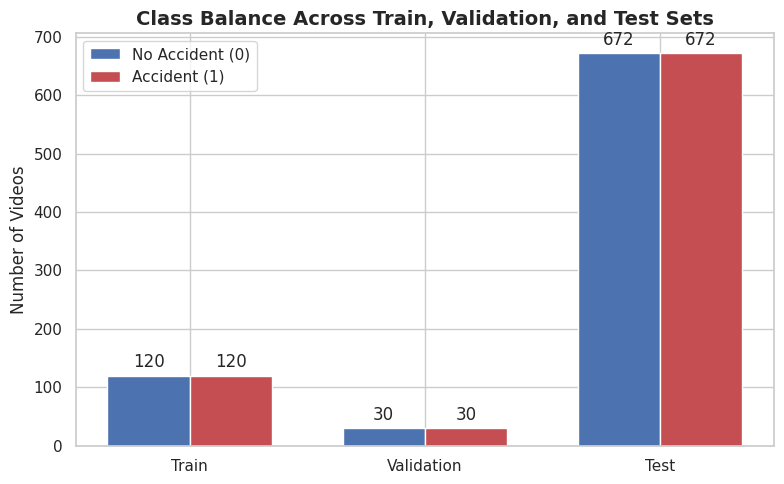


========== METADATA LEAKAGE AUDIT ==========


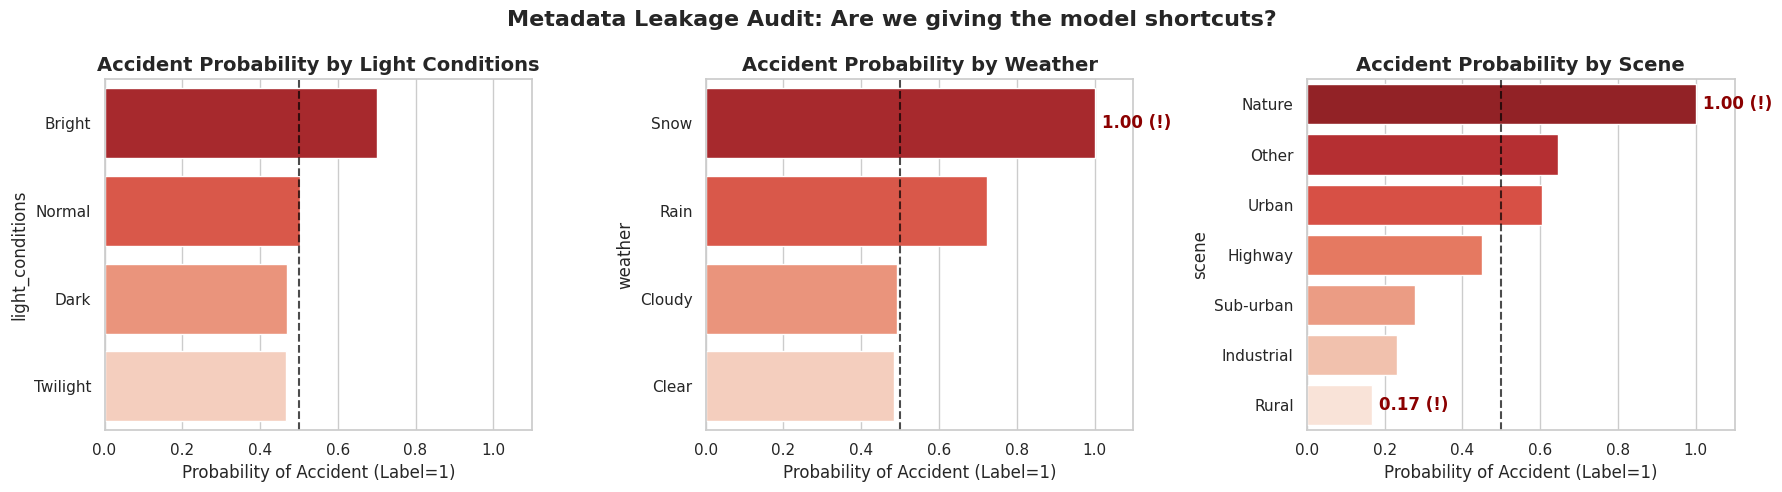


========== POSITIVE VS NEGATIVE ENVIRONMENT DISTRIBUTIONS ==========


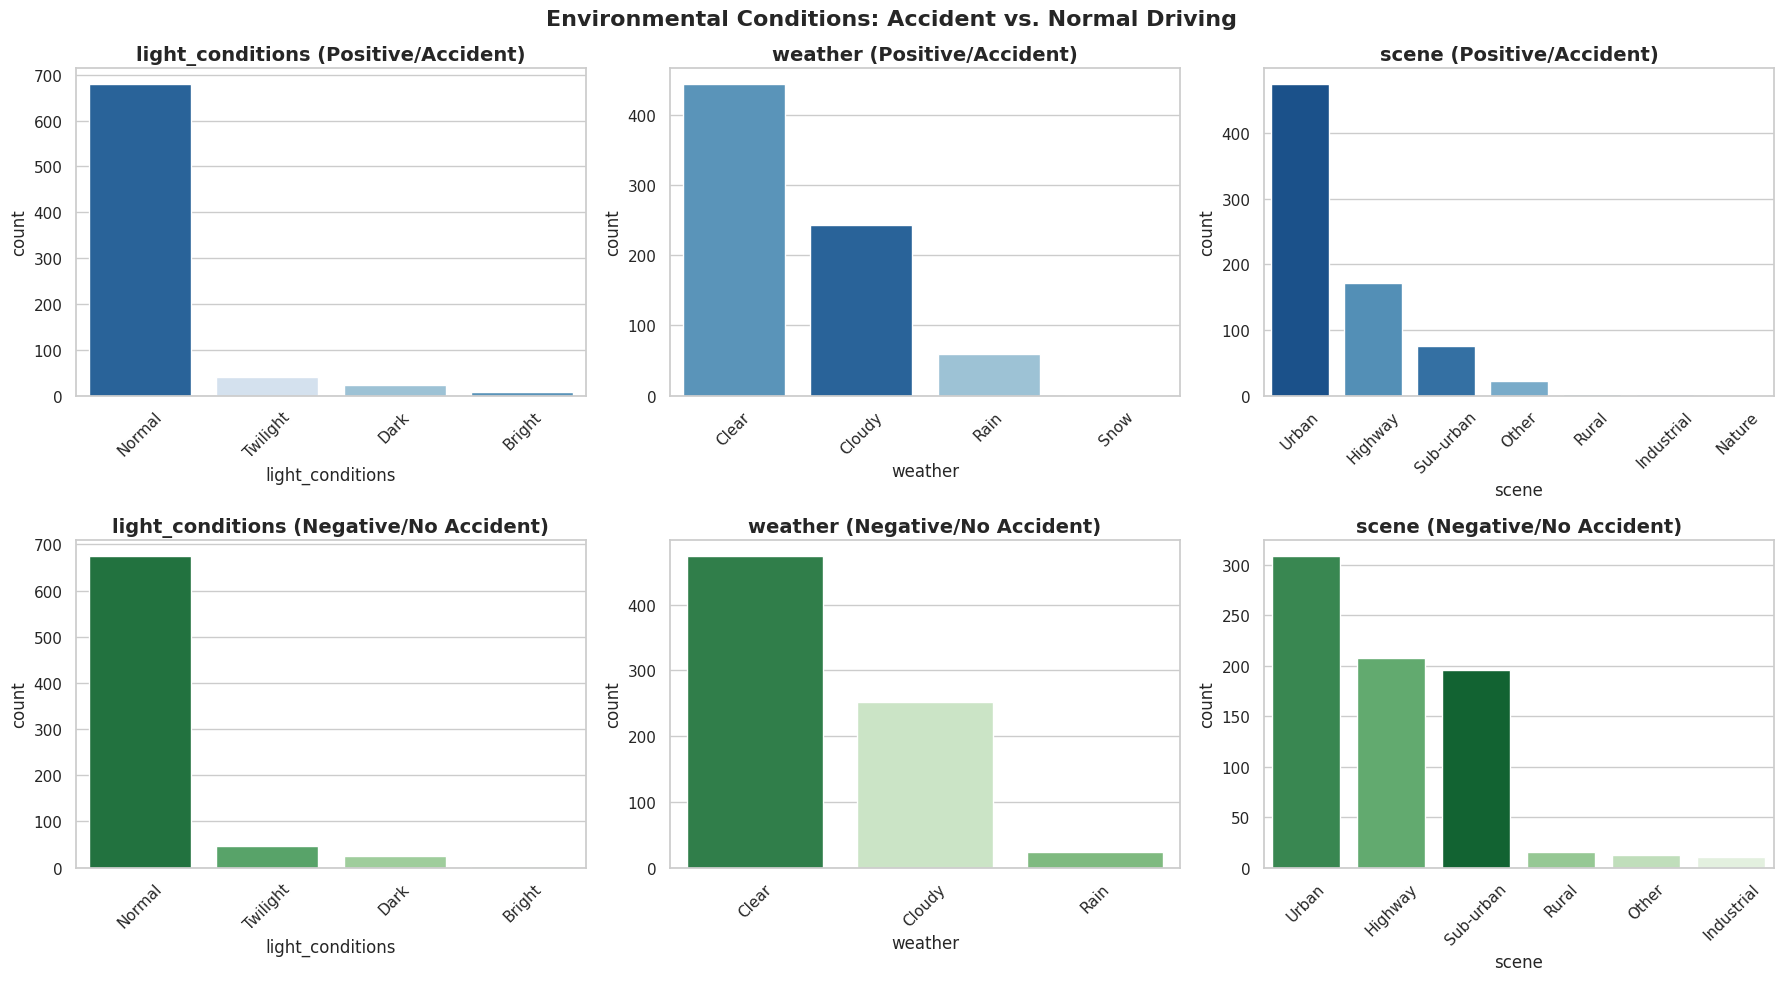


========== TIME OF EVENT DISTRIBUTION ==========


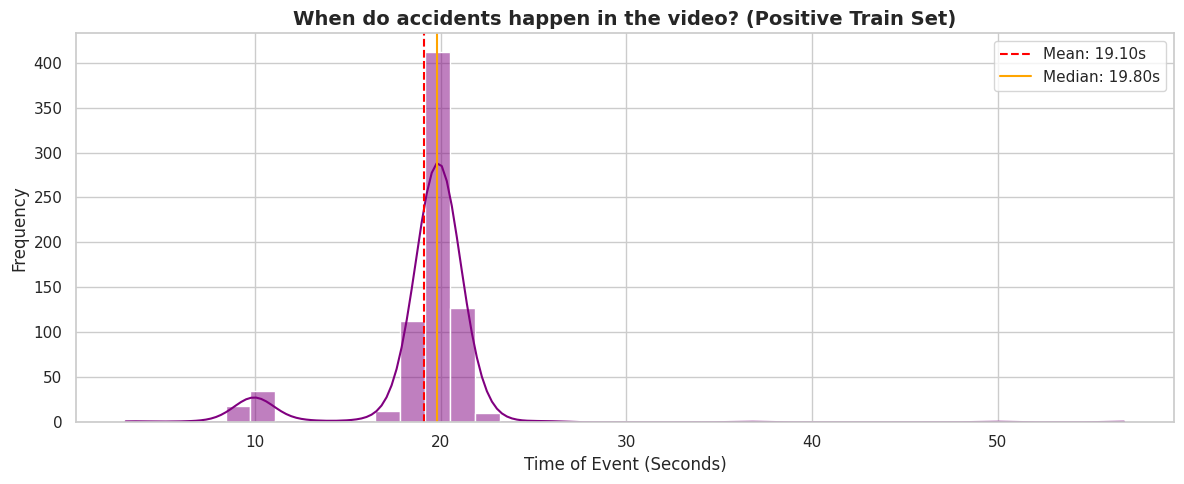

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set a beautiful, professional style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14, 'axes.titleweight': 'bold'})

# ==========================================
# 1. CLASS BALANCE ACROSS SPLITS
# ==========================================
print("========== CLASS BALANCE ACROSS SPLITS ==========")
splits = ['Train', 'Validation', 'Test']
counts_0 = [sum(final_train['label']==0), sum(final_val['label']==0), sum(final_test['label']==0)]
counts_1 = [sum(final_train['label']==1), sum(final_val['label']==1), sum(final_test['label']==1)]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(splits))
width = 0.35

rects1 = ax.bar(x - width/2, counts_0, width, label='No Accident (0)', color='#4C72B0')
rects2 = ax.bar(x + width/2, counts_1, width, label='Accident (1)', color='#C44E52')

ax.set_ylabel('Number of Videos')
ax.set_title('Class Balance Across Train, Validation, and Test Sets')
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.legend()
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)
plt.tight_layout()
plt.show()

# ==========================================
# 2. METADATA LEAKAGE AUDIT (Visualized)
# ==========================================
print("\n========== METADATA LEAKAGE AUDIT ==========")
df_pos = prepared_metadata['train/positive/metadata.csv']
df_neg = prepared_metadata['train/negative/metadata.csv']
df_all_train = pd.concat([df_pos, df_neg])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    leakage_check = df_all_train.groupby(col)['label'].mean().sort_values(ascending=False)

    # FIX 1: Added hue and legend=False to fix the Seaborn FutureWarning
    sns.barplot(x=leakage_check.values, y=leakage_check.index, ax=axes[i],
                hue=leakage_check.index, palette="Reds_r", legend=False)

    axes[i].axvline(0.5, color='black', linestyle='--', alpha=0.7)
    axes[i].set_title(f'Accident Probability by {col.replace("_", " ").title()}')
    axes[i].set_xlabel('Probability of Accident (Label=1)')
    axes[i].set_xlim(0, 1.1)

    # FIX 2: Replaced the ⚠️ emoji with "(!)" so the Windows font can display it
    for j, v in enumerate(leakage_check.values):
        if v > 0.8 or v < 0.2:
            axes[i].text(v + 0.02, j, f"{v:.2f} (!)", va='center', fontweight='bold', color='darkred')

plt.suptitle('Metadata Leakage Audit: Are we giving the model shortcuts?', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 3. POSITIVE VS NEGATIVE DISTRIBUTIONS
# ==========================================
print("\n========== POSITIVE VS NEGATIVE ENVIRONMENT DISTRIBUTIONS ==========")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    # Positive Plot (FIXED)
    sns.countplot(data=df_pos, x=col, ax=axes[0, i], order=df_pos[col].value_counts().index,
                  hue=col, palette="Blues_r", legend=False)
    axes[0, i].set_title(f'{col} (Positive/Accident)')
    axes[0, i].tick_params(axis='x', rotation=45)

    # Negative Plot (FIXED)
    sns.countplot(data=df_neg, x=col, ax=axes[1, i], order=df_neg[col].value_counts().index,
                  hue=col, palette="Greens_r", legend=False)
    axes[1, i].set_title(f'{col} (Negative/No Accident)')
    axes[1, i].tick_params(axis='x', rotation=45)
plt.suptitle('Environmental Conditions: Accident vs. Normal Driving', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 4. TIME OF EVENT DISTRIBUTION
# ==========================================
print("\n========== TIME OF EVENT DISTRIBUTION ==========")
plt.figure(figsize=(12, 5))
sns.histplot(data=metadata_dfs['train/positive/metadata.csv'], x='time_of_event', bins=40, kde=True, color='purple')
mean_time = metadata_dfs['train/positive/metadata.csv']['time_of_event'].mean()
median_time = metadata_dfs['train/positive/metadata.csv']['time_of_event'].median()
plt.axvline(mean_time, color='red', linestyle='--', label=f'Mean: {mean_time:.2f}s')
plt.axvline(median_time, color='orange', linestyle='-', label=f'Median: {median_time:.2f}s')

plt.title('When do accidents happen in the video? (Positive Train Set)')
plt.xlabel('Time of Event (Seconds)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

برای جلوگیری از **Data Leakage**، ستون‌های `time_of_event`، `time_of_alert` و `time_to_accident` نباید وارد مدل شوند، چون اطلاعات مربوط به وقوع حادثه را آشکار می‌کنند یا برای آموزش مفید نیستند.

همچنین ستون‌های `weather`، `scene` و `light_conditions` فقط برای تحلیل داده‌ها و نمونه‌گیری استفاده می‌شوند و `file_name` و `video_path` صرفاً برای شناسایی و بارگذاری ویدئوها هستند.

**ورودی مدل فقط فریم‌های ویدئو است** و ستون `label` صرفاً به‌عنوان پاسخ واقعی برای آموزش و ارزیابی استفاده می‌شود.

Uniform Temporal Sampling

In [11]:
import cv2
import numpy as np

FRAME_INTERVAL = 0.2
IMAGE_SIZE = (224, 224)


def extract_frames(video_path):
    cap = cv2.VideoCapture(str(video_path))

    try:
        if not cap.isOpened():
            raise ValueError(f"Cannot open video: {video_path}")

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)

        if (
            not np.isfinite(fps)
            or fps <= 0
            or not np.isfinite(frame_count)
            or frame_count < 1
        ):
            raise ValueError(f"Invalid video metadata: {video_path}")

        total_frames = int(frame_count)
        duration = total_frames / fps

        # Sample at 0, 0.2, 0.4, 0.6, ... seconds.
        target_times = np.arange(0, duration, FRAME_INTERVAL)

        indices = np.rint(target_times * fps).astype(np.int64)
        indices = np.unique(indices[indices < total_frames])

        if len(indices) == 0:
            raise ValueError(f"No frames available: {video_path}")

        wanted = set(indices.tolist())
        last = int(indices[-1])
        frames = []
        pos = 0

        while pos <= last:
            ok = cap.grab()

            if not ok:
                raise ValueError(
                    f"Cannot read frame {pos}: {video_path}"
                )

            if pos in wanted:
                ok, frame = cap.retrieve()

                if not ok:
                    raise ValueError(
                        f"Cannot read frame {pos}: {video_path}"
                    )

                frame = cv2.resize(
                    frame,
                    IMAGE_SIZE,
                    interpolation=cv2.INTER_AREA
                )

                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(frame)

            pos += 1

        timestamps = indices / fps

        return np.stack(frames), timestamps, indices

    finally:
        cap.release()

ازمایش فریم گیری


Video: 00655.mp4
Frames shape: (199, 224, 224, 3)
Extracted frames: 199
Sampling interval (seconds): 0.2
First timestamp: 0.0
Last timestamp: 39.59459459459459


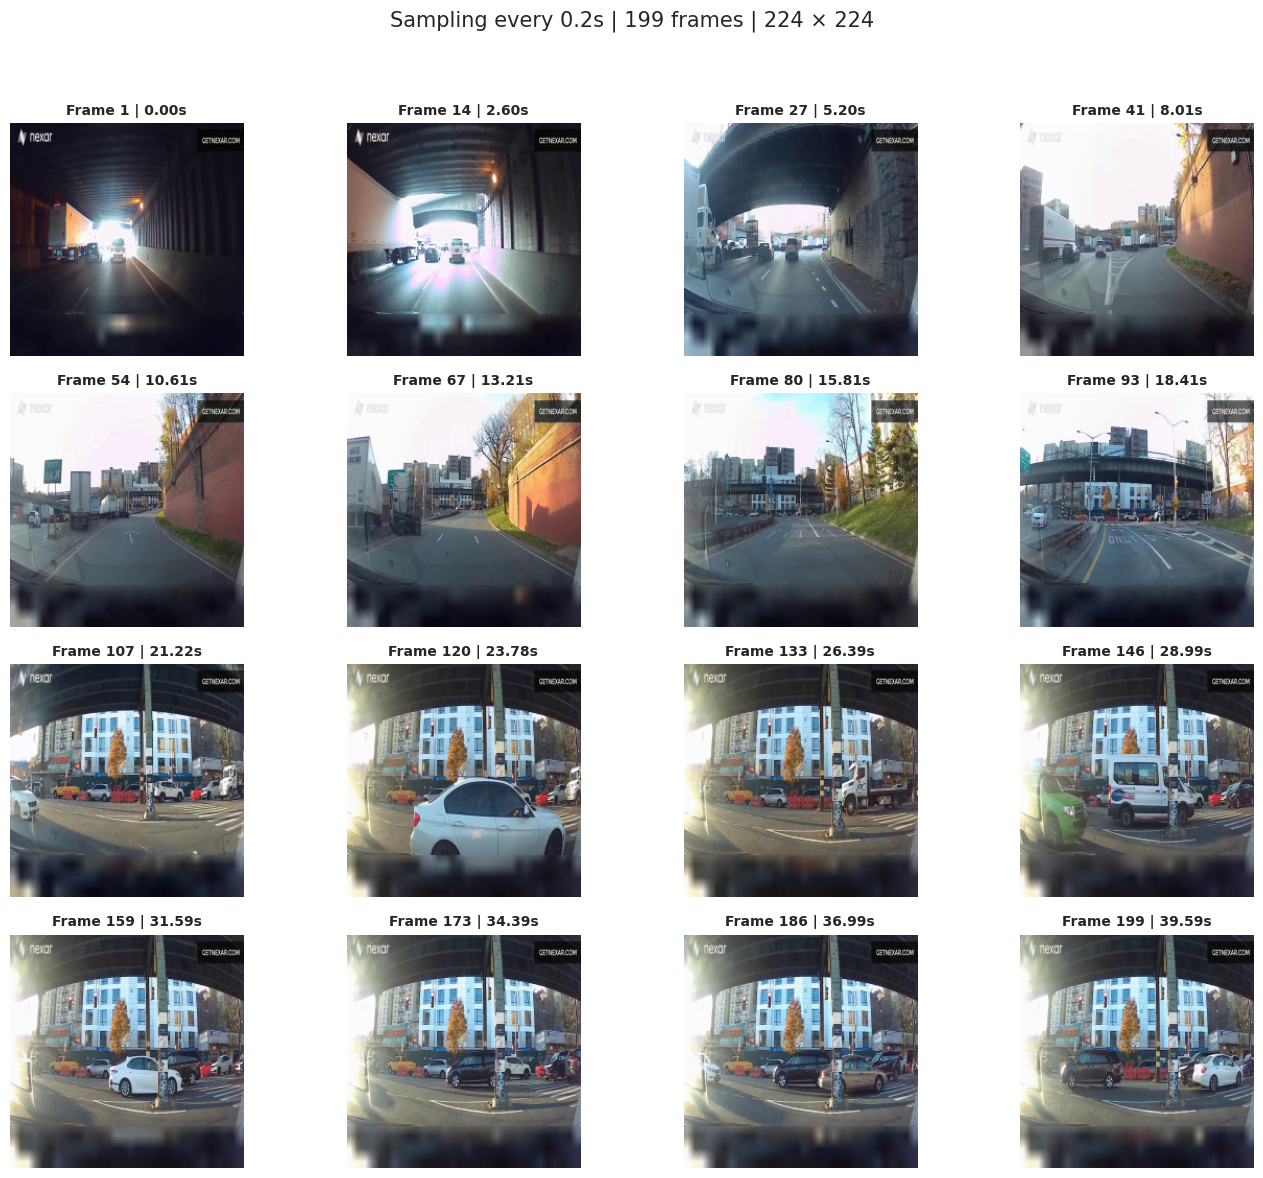

In [12]:
from huggingface_hub import hf_hub_download
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ID = "nexar-ai/nexar_collision_prediction"

# خواندن متادیتای ترین
train_df = pd.read_csv("data/processed_v2/train_240.csv")

# انتخاب یک ویدئوی مثبت برای بررسی
sample = train_df[train_df["label"] == 1].iloc[0]

# استفاده از ویدئوی کش‌شده یا دانلود آن
video_path = get_video(sample["video_path"])

# استخراج با تابع جدید سلول ۱۷
frames, timestamps, indices = extract_frames(video_path)

print("Video:", sample["file_name"])
print("Frames shape:", frames.shape)
print("Extracted frames:", len(frames))
print("Sampling interval (seconds):", FRAME_INTERVAL)
print("First timestamp:", timestamps[0])
print("Last timestamp:", timestamps[-1])

assert frames.shape[1:] == (224, 224, 3)

# نمایش حداکثر ۱۶ فریم از سراسر ویدئو
shown = np.linspace(
    0, len(frames) - 1, min(16, len(frames))
).round().astype(int)

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, i in zip(axes.flat, shown):
    ax.imshow(frames[i])
    ax.set_title(
        f"Frame {i + 1} | {timestamps[i]:.2f}s",
        fontsize=10
    )

fig.suptitle(
    f"Sampling every {FRAME_INTERVAL}s | "
    f"{len(frames)} frames | 224 × 224",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
# Keep only the preview plot; release the temporary array.
del frames, timestamps, indices


استخراج ویدیو

In [13]:
from pathlib import Path
from time import perf_counter

import cv2
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download


REPO_ID = "nexar-ai/nexar_collision_prediction"

# تمام خروجی‌های نهایی داخل همین پوشه هستند.
FRAME_DIR = Path("data/preprocessed_300_0p2s_224").resolve()
CACHE_DIR = PROJECT_DIR / "data/video_cache"

TRAIN_CSV = FRAME_DIR / "train_240.csv"
VAL_CSV = FRAME_DIR / "val_60.csv"

FRAME_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

PREPROCESSING_OK = False

assert FRAME_INTERVAL == 0.2
assert IMAGE_SIZE == (224, 224)

# نام CSVهای قبلی مهم نیست؛ تعداد واقعی بررسی می‌شود.
train_df = pd.read_csv(
    "data/processed_v2/train_240.csv",
    dtype={"file_name": str, "video_path": str}
)

val_df = pd.read_csv(
    "data/processed_v2/val_60.csv",
    dtype={"file_name": str, "video_path": str}
)

assert len(train_df) == 240
assert len(val_df) == 60

assert train_df["label"].value_counts().to_dict() == {0: 120, 1: 120}
assert val_df["label"].value_counts().to_dict() == {0: 30, 1: 30}

df = pd.concat([train_df, val_df], ignore_index=True)

assert df["video_path"].notna().all()
assert df["video_path"].is_unique
assert df["file_name"].is_unique

assert set(train_df["video_path"]).isdisjoint(
    set(val_df["video_path"])
)


def frame_file(video_path):
    return FRAME_DIR / Path(video_path).with_suffix(".npz")


def verify_npz(path, expected_label, expected_video_path):
    """بررسی فایل ذخیره‌شده و کامل بودن برنامهٔ نمونه‌گیری."""

    with np.load(path, allow_pickle=False) as data:
        required = {
            "frames", "timestamps", "indices",
            "label", "frame_interval",
            "fps", "total_frames", "video_path"
        }

        missing = required - set(data.files)
        if missing:
            raise ValueError(f"Missing keys: {sorted(missing)}")

        frames = data["frames"]
        timestamps = data["timestamps"]
        indices = data["indices"]

        fps = float(data["fps"].item())
        total_frames = int(data["total_frames"].item())

        assert np.isfinite(fps) and fps > 0, "Invalid FPS"
        assert total_frames > 0, "Invalid source frame count"

        assert data["video_path"].item() == expected_video_path, \
            "Video identity mismatch"

        assert data["label"].item() == expected_label, \
            "Label mismatch"

        assert np.isclose(
            data["frame_interval"].item(),
            FRAME_INTERVAL,
            rtol=0,
            atol=1e-9
        ), "Sampling interval mismatch"

        assert frames.ndim == 4, "Invalid frame dimensions"
        assert len(frames) > 0, "Empty frames"
        assert frames.shape[1:] == (224, 224, 3), "Invalid image size"
        assert frames.dtype == np.uint8, "Invalid pixel dtype"

        assert timestamps.shape == indices.shape == (len(frames),), \
            "Frames / timestamps / indices length mismatch"

        assert np.issubdtype(indices.dtype, np.integer), \
            "Frame indices must be integers"

        assert np.isfinite(timestamps).all(), "Invalid timestamps"

        # همان برنامهٔ نمونه‌گیری تابع extract_frames،
        # از زمان صفر تا انتهای مدت ویدیو.
        target_times = np.arange(
            0,
            total_frames / fps,
            FRAME_INTERVAL
        )

        expected_indices = np.rint(
            target_times * fps
        ).astype(np.int64)

        expected_indices = np.unique(
            expected_indices[expected_indices < total_frames]
        )

        assert np.array_equal(indices, expected_indices), \
            "Incomplete or incorrect sampling"

        assert np.allclose(
            timestamps,
            expected_indices / fps,
            rtol=0,
            atol=1e-6
        ), "Incorrect timestamps"

        return len(frames)


completed = 0
reused = 0
failed = []

print("Output folder:", FRAME_DIR, flush=True)

for i, row in enumerate(df.itertuples(index=False), start=1):
    output = frame_file(row.video_path)
    temporary = LOCAL_NPZ_DIR / Path(row.video_path).with_suffix(".tmp.npz")
    temporary.parent.mkdir(parents=True, exist_ok=True)
    started = perf_counter()

    try:
        # صرفاً موجود بودن فایل کافی نیست.
        if output.exists():
            try:
                n_frames = verify_npz(
                    output, int(row.label), row.video_path
                )
            except Exception as error:
                print(
                    f"[{i}/{len(df)}] REBUILD | "
                    f"{row.video_path} | {error}",
                    flush=True
                )
            else:
                reused += 1
                print(
                    f"[{i}/{len(df)}] ALREADY DONE | OK | "
                    f"{row.video_path} | {n_frames} frames",
                    flush=True
                )
                continue

        print(
            f"[{i}/{len(df)}] PROCESSING | {row.video_path}",
            flush=True
        )

        video = get_video(row.video_path)

        # ثبت مشخصات منبع برای بررسی پوشش کامل نمونه‌گیری.
        cap = cv2.VideoCapture(str(video))

        try:
            if not cap.isOpened():
                raise ValueError(f"Cannot open video: {video}")

            fps = cap.get(cv2.CAP_PROP_FPS)
            frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        finally:
            cap.release()

        if (
            not np.isfinite(fps)
            or fps <= 0
            or not np.isfinite(frame_count)
            or frame_count < 1
        ):
            raise ValueError("Invalid source video metadata")

        total_frames = int(frame_count)

        # همان تابع فعلی تو؛ ساختار while تغییر نکرده است.
        frames, timestamps, indices = extract_frames(video)

        output.parent.mkdir(parents=True, exist_ok=True)

        # ابتدا فایل موقت؛ سپس بررسی؛ در آخر جایگزینی خروجی.
        np.savez_compressed(
            temporary,
            frames=frames,
            timestamps=timestamps,
            indices=indices,
            label=int(row.label),
            frame_interval=FRAME_INTERVAL,
            fps=fps,
            total_frames=total_frames,
            video_path=row.video_path
        )

        del frames, timestamps, indices

        n_frames = verify_npz(
            temporary, int(row.label), row.video_path
        )

        publish_file(temporary, output)
        temporary.unlink(missing_ok=True)
        completed += 1

        print(
            f"[{i}/{len(df)}] DONE | OK | "
            f"{row.video_path} | {n_frames} frames | "
            f"{perf_counter() - started:.1f}s",
            flush=True
        )

    except Exception as error:
        temporary.unlink(missing_ok=True)
        failed.append((row.video_path, str(error)))

        print(
            f"[{i}/{len(df)}] FAILED | "
            f"{row.video_path} | {error}",
            flush=True
        )


print("\n========== EXTRACTION RESULTS ==========")
print("Created and verified:", completed)
print("Previously verified:", reused)
print("Failed:", len(failed))
print(f"Verified: {completed + reused}/{len(df)}")
print("Output folder:", FRAME_DIR)

if failed:
    display(pd.DataFrame(failed, columns=["video_path", "error"]))
    raise RuntimeError(
        "Some videos failed. Resolve the reported errors and rerun "
        "this cell; verified files will be reused."
    )

Output folder: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224
[1/300] ALREADY DONE | OK | train/negative/01342.mp4 | 201 frames
[2/300] ALREADY DONE | OK | train/negative/02132.mp4 | 214 frames
[3/300] ALREADY DONE | OK | train/negative/01429.mp4 | 201 frames
[4/300] ALREADY DONE | OK | train/positive/00655.mp4 | 199 frames
[5/300] ALREADY DONE | OK | train/negative/01230.mp4 | 196 frames
[6/300] ALREADY DONE | OK | train/negative/01953.mp4 | 199 frames


KeyboardInterrupt: 

In [14]:
PREPROCESSING_OK = False

problems = []
frame_counts = []

for i, row in enumerate(df.itertuples(index=False), start=1):
    try:
        n_frames = verify_npz(
            frame_file(row.video_path),
            int(row.label),
            row.video_path
        )

        frame_counts.append(n_frames)

    except Exception as error:
        problems.append((row.video_path, str(error)))

    if i % 25 == 0 or i == len(df):
        print(
            f"Checked: {i}/{len(df)} | Problems: {len(problems)}",
            flush=True
        )

if problems:
    display(pd.DataFrame(problems, columns=["video_path", "error"]))
    raise RuntimeError(
        "Preprocessing validation failed. "
        "Rerun the extraction cell to rebuild invalid files."
    )

assert len(frame_counts) == 300

# خروجی‌های مخصوص بارگذاری داده:
# اطلاعات زمانی حادثه و شرایط محیطی وارد این CSVها نمی‌شوند.
for source_df, csv_path in [
    (train_df, TRAIN_CSV),
    (val_df, VAL_CSV)
]:
    manifest = source_df[
        ["file_name", "video_path", "label"]
    ].copy()

    # مسیر نسبت به FRAME_DIR است.
    manifest["frame_path"] = manifest["video_path"].map(
        lambda value: Path(value).with_suffix(".npz").as_posix()
    )

    temporary_csv = csv_path.with_suffix(".tmp.csv")
    manifest.to_csv(temporary_csv, index=False)
    temporary_csv.replace(csv_path)

PREPROCESSING_OK = True

print("\nALL FILES VERIFIED | OK")
print("Train: 240 | Validation: 60")
print("Frames per video:", min(frame_counts), "to", max(frame_counts))
print("Saved frame format: RGB, uint8, (T, 224, 224, 3)")
print("Target sampling interval: 0.2 seconds")
print("Train CSV:", TRAIN_CSV)
print("Validation CSV:", VAL_CSV)
print("Frame folder:", FRAME_DIR)

Checked: 25/300 | Problems: 0
Checked: 50/300 | Problems: 0
Checked: 75/300 | Problems: 0
Checked: 100/300 | Problems: 0
Checked: 125/300 | Problems: 0
Checked: 150/300 | Problems: 0
Checked: 175/300 | Problems: 0
Checked: 200/300 | Problems: 0
Checked: 225/300 | Problems: 0
Checked: 250/300 | Problems: 0
Checked: 275/300 | Problems: 0
Checked: 300/300 | Problems: 0

ALL FILES VERIFIED | OK
Train: 240 | Validation: 60
Frames per video: 90 to 300
Saved frame format: RGB, uint8, (T, 224, 224, 3)
Target sampling interval: 0.2 seconds
Train CSV: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224/train_240.csv
Validation CSV: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224/val_60.csv
Frame folder: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224


نرمال سازی پیکسلها

In [15]:
import torch
print("Using existing PyTorch:", torch.__version__)
print("No PyTorch/CUDA reinstallation is needed for preprocessing.")


Using existing PyTorch: 2.11.0+cpu
No PyTorch/CUDA reinstallation is needed for preprocessing.


In [16]:
import numpy as np
import pandas as pd
from pathlib import Path
from torch.utils.data import Dataset


class NormalizedVideoDataset(Dataset):

    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path)
        self.frame_dir = Path("data/preprocessed_300_0p2s_224")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        file_path = (
            self.frame_dir
            / Path(row["video_path"]).with_suffix(".npz")
        )

        with np.load(file_path, allow_pickle=False) as data:
            frames = data["frames"]

        # Scale pixels from [0, 255] to [0, 1].
        frames = frames.astype(np.float32) / 255.0

        return frames, int(row["label"])


train_dataset = NormalizedVideoDataset(
    "data/processed_v2/train_240.csv"
)

val_dataset = NormalizedVideoDataset(
    "data/processed_v2/val_60.csv"
)

frames, label = train_dataset[0]

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Frames shape:", frames.shape)
print("Min pixel:", frames.min())
print("Max pixel:", frames.max())
print("Data type:", frames.dtype)

Train samples: 240
Validation samples: 60
Frames shape: (201, 224, 224, 3)
Min pixel: 0.0
Max pixel: 1.0
Data type: float32


data agumentation

In [17]:
import numpy as np
import torch
import pandas as pd
from pathlib import Path
from torch.utils.data import Dataset


FRAME_DIR = Path("data/preprocessed_300_0p2s_224").resolve()

TRAIN_CSV = FRAME_DIR / "train_240.csv"
VAL_CSV = FRAME_DIR / "val_60.csv"


def video_augmentation(frames, probability=0.5):
    if np.random.random() >= probability:
        return frames

    # Apply the same adjustment to every frame of one video.
    brightness = np.random.uniform(0.9, 1.1)
    contrast = np.random.uniform(0.9, 1.1)

    frames = (frames - 0.5) * contrast + 0.5
    frames = frames * brightness
    frames = np.clip(frames, 0.0, 1.0)

    return frames.astype(np.float32)


class AccidentVideoDataset(Dataset):

    def __init__(self, csv_path, frame_dir, augment=False):
        self.df = pd.read_csv(csv_path)
        self.frame_dir = Path(frame_dir)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        frame_path = (
            self.frame_dir
            / Path(row["video_path"]).with_suffix(".npz")
        )

        with np.load(frame_path, allow_pickle=False) as data:
            frames = data["frames"]

        # Normalize pixels from [0, 255] to [0, 1].
        frames = frames.astype(np.float32) / 255.0

        if self.augment:
            frames = video_augmentation(frames)

        # [T, H, W, C] -> [T, C, H, W]
        frames = torch.from_numpy(
            np.ascontiguousarray(frames)
        ).permute(0, 3, 1, 2).contiguous()

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return frames, label


train_dataset = AccidentVideoDataset(
    csv_path=TRAIN_CSV,
    frame_dir=FRAME_DIR,
    augment=True
)

val_dataset = AccidentVideoDataset(
    csv_path=VAL_CSV,
    frame_dir=FRAME_DIR,
    augment=False
)

assert len(train_dataset) == 240
assert len(val_dataset) == 60

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Train Augmentation: Enabled")
print("Validation Augmentation: Disabled")
print("Frame folder:", FRAME_DIR)

Train samples: 240
Validation samples: 60
Train Augmentation: Enabled
Validation Augmentation: Disabled
Frame folder: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224


بررسی مجدد توازن


,No Accident (0),Accident (1)
Train,120,120
Validation,30,30



Class Balance (%):


,No Accident (0),Accident (1)
Train,50.0,50.0
Validation,50.0,50.0


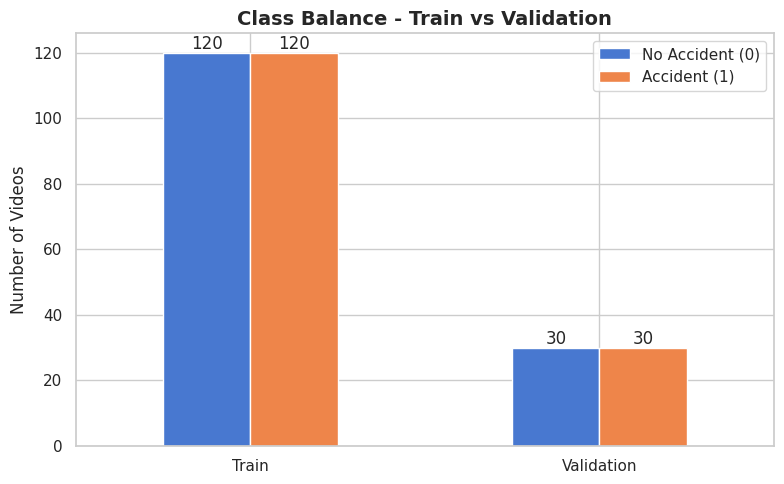

✅ Classes are balanced. No class weighting needed.


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("data/processed_v2/train_240.csv")
val = pd.read_csv("data/processed_v2/val_60.csv")

# Class Distribution
counts = pd.DataFrame({
    "Train": train["label"].value_counts(),
    "Validation": val["label"].value_counts()
}).T.reindex(columns=[0, 1], fill_value=0)

counts.columns = ["No Accident (0)", "Accident (1)"]

# Display counts and percentages
display(counts)
print("\nClass Balance (%):")
display(counts.div(counts.sum(axis=1), axis=0) * 100)

# Plot
ax = counts.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Class Balance - Train vs Validation")
ax.set_ylabel("Number of Videos")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.tight_layout()
plt.show()

# Final Check
if (counts.iloc[:, 0] == counts.iloc[:, 1]).all():
    print("✅ Classes are balanced. No class weighting needed.")
else:
    print("⚠️ Class imbalance detected. Review class ratios.")

بررسی نهایی

In [19]:
assert PREPROCESSING_OK, \
    "Run extraction and final validation successfully first."

assert TRAIN_CSV.is_file()
assert VAL_CSV.is_file()

print("PREPROCESSING COMPLETED | OK")
print("Verified videos: 300")
print("Train: 240")
print("Validation: 60")
print("Frame size: 224 × 224")
print("Target sampling interval: 0.2 seconds")
print("Sampling scope: entire video")
print("Saved pixels: RGB / uint8 / 0–255")
print("Output folder:", FRAME_DIR)
print("Train CSV:", TRAIN_CSV)
print("Validation CSV:", VAL_CSV)
print("Project on Drive:", PROJECT_DIR)
print("Original videos on Drive:", CACHE_DIR)
print("Recorded settings:", config_path)


PREPROCESSING COMPLETED | OK
Verified videos: 300
Train: 240
Validation: 60
Frame size: 224 × 224
Target sampling interval: 0.2 seconds
Sampling scope: entire video
Saved pixels: RGB / uint8 / 0–255
Output folder: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224
Train CSV: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224/train_240.csv
Validation CSV: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224/val_60.csv
Project on Drive: /content/drive/MyDrive/DL-Project/image_neural_network
Original videos on Drive: /content/drive/MyDrive/DL-Project/image_neural_network/data/video_cache
Recorded settings: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessing_config_300.json


In [20]:
import hashlib
import json
import numpy as np
import pandas as pd
from pathlib import Path

base_train = pd.read_csv(FRAME_DIR / "train_240.csv")
base_val = pd.read_csv(FRAME_DIR / "val_60.csv")
base = pd.concat([base_train, base_val], ignore_index=True)

assert len(base_train) == 240 and len(base_val) == 60
assert base_train["label"].value_counts().to_dict() == {0: 120, 1: 120}
assert base_val["label"].value_counts().to_dict() == {0: 30, 1: 30}
assert base["video_path"].is_unique

base_signature = hashlib.sha256(
    base[["video_path", "label"]].to_csv(index=False).encode()
).hexdigest()

plan_path = PROJECT_DIR / "data/processed_v2/extension_130.json"

if plan_path.exists():
    saved_plan = json.loads(plan_path.read_text())
    assert saved_plan["base_signature"] == base_signature
    assert saved_plan["revision"] == DATASET_REVISION
    additions = pd.DataFrame(saved_plan["rows"])

else:
    seen = set(base["video_path"])

    for p in FRAME_DIR.rglob("*.npz"):
        seen.add(
            p.relative_to(FRAME_DIR).with_suffix(".mp4").as_posix()
        )

    for p in CACHE_DIR.rglob("*.mp4"):
        seen.add(p.relative_to(CACHE_DIR).as_posix())

    for pattern in ("sample*.csv", "train*.csv", "val*.csv", "test*.csv"):
        for p in (PROJECT_DIR / "data").glob("processed*/" + pattern):
            table = pd.read_csv(p)
            if "video_path" in table:
                seen.update(table["video_path"].dropna())

    pool = full_train.loc[
        ~full_train["video_path"].isin(seen)
    ].copy()

    parts = []

    for label in (0, 1):
        available = pool.loc[pool["label"].eq(label)]

        # First reserve 15 fresh test videos per class.
        test_part = proportional_sample(
            available, 15, 2026 + label
        )

        available = available.loc[
            ~available["video_path"].isin(test_part["video_path"])
        ]

        train_part = proportional_sample(
            available, 50, 2028 + label
        )

        parts.extend([
            test_part.assign(split="test"),
            train_part.assign(split="train"),
        ])

    additions = pd.concat(parts, ignore_index=True)[
        ["video_path", "label", "split"]
    ]

    plan_path.parent.mkdir(parents=True, exist_ok=True)
    temporary_plan = plan_path.with_suffix(".tmp.json")

    temporary_plan.write_text(json.dumps({
        "base_signature": base_signature,
        "revision": DATASET_REVISION,
        "rows": additions.to_dict("records"),
    }, indent=2))

    temporary_plan.replace(plan_path)

assert len(additions) == 130
assert additions["video_path"].is_unique
assert set(additions["video_path"]).isdisjoint(base["video_path"])
assert additions["split"].isin(["train", "test"]).all()

for split, per_class in [("train", 50), ("test", 15)]:
    counts = additions.loc[
        additions["split"].eq(split), "label"
    ].value_counts().to_dict()

    assert counts == {0: per_class, 1: per_class}

truth = full_train.set_index("video_path")["label"]

assert all(
    truth.at[p] == y
    for p, y in additions[["video_path", "label"]].itertuples(
        index=False, name=None
    )
)

print(additions.groupby(["split", "label"]).size())
print("Plan saved. Old 240/60 split preserved.")

split  label
test   0        15
       1        15
train  0        50
       1        50
dtype: int64
Plan saved. Old 240/60 split preserved.


In [21]:
import cv2
from huggingface_hub import hf_hub_download

assert FRAME_INTERVAL == 0.2
assert IMAGE_SIZE == (224, 224)

# Current free Drive space, in decimal GB.
# Update this number before each new execution.
DRIVE_FREE_GB = 4.5
RESERVE_GB = 0.5

budget = int((DRIVE_FREE_GB - RESERVE_GB) * 1e9)
assert budget > 0

pending = [
    row for row in additions.itertuples(index=False)
    if not frame_file(row.video_path).exists()
]

old_sizes = [
    frame_file(p).stat().st_size for p in base["video_path"]
]
estimate = float(np.mean(old_sizes)) * len(pending)

print(
    f"Pending: {len(pending)} | "
    f"Estimated extra frames: {estimate / 1e9:.2f} GB"
)

if estimate > budget:
    raise OSError(
        "Insufficient safety margin. Free more Drive space, "
        "update DRIVE_FREE_GB, and rerun this cell."
    )

written = 0

for i, row in enumerate(additions.itertuples(index=False), 1):
    output = frame_file(row.video_path)

    if output.exists():
        verify_npz(output, int(row.label), row.video_path)
        print(f"[{i}/130] REUSED", flush=True)
        continue

    video = Path(hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=row.video_path,
        revision=DATASET_REVISION,
        token=HF_TOKEN,
        local_dir=str(LOCAL_ROOT / "extension_videos"),
    ))

    temporary = (
        LOCAL_NPZ_DIR
        / Path(row.video_path).with_suffix(".tmp.npz")
    )
    temporary.parent.mkdir(parents=True, exist_ok=True)

    try:
        cap = cv2.VideoCapture(str(video))
        try:
            assert cap.isOpened(), f"Cannot open {video}"
            fps = float(cap.get(cv2.CAP_PROP_FPS))
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        finally:
            cap.release()

        frames, timestamps, indices = extract_frames(video)

        np.savez_compressed(
            temporary,
            frames=frames,
            timestamps=timestamps,
            indices=indices,
            label=int(row.label),
            frame_interval=FRAME_INTERVAL,
            fps=fps,
            total_frames=total_frames,
            video_path=row.video_path,
        )
        del frames, timestamps, indices

        verify_npz(temporary, int(row.label), row.video_path)

        size = temporary.stat().st_size
        if written + size > budget:
            raise OSError(
                "Drive budget reached. Free space and update "
                "DRIVE_FREE_GB before resuming."
            )

        publish_file(temporary, output)
        written += size

        print(
            f"[{i}/130] CREATED | {size / 1e6:.1f} MB",
            flush=True,
        )

    finally:
        temporary.unlink(missing_ok=True)
        # Deletes only the new temporary local video.
        video.unlink(missing_ok=True)

for row in additions.itertuples(index=False):
    verify_npz(
        frame_file(row.video_path), int(row.label), row.video_path
    )


def make_manifest(frame):
    result = frame[["video_path", "label"]].copy()
    result["file_name"] = result["video_path"].map(
        lambda p: Path(p).name
    )
    result["frame_path"] = result["video_path"].map(
        lambda p: Path(p).with_suffix(".npz").as_posix()
    )
    return result[["file_name", "video_path", "label", "frame_path"]]


train_340 = make_manifest(pd.concat([
    base_train,
    additions.loc[additions["split"].eq("train")],
], ignore_index=True))

test_30 = make_manifest(
    additions.loc[additions["split"].eq("test")]
)

assert len(train_340) == 340 and len(test_30) == 30
assert train_340["label"].value_counts().to_dict() == {0: 170, 1: 170}

all_ids = pd.concat([train_340, base_val, test_30])["video_path"]
assert len(all_ids) == 430 and all_ids.is_unique

for name, table in [
    ("train_340.csv", train_340),
    ("test_30.csv", test_30),
]:
    temporary_csv = LOCAL_NPZ_DIR / name
    try:
        table.to_csv(temporary_csv, index=False)
        publish_file(temporary_csv, FRAME_DIR / name)
    finally:
        temporary_csv.unlink(missing_ok=True)

print("EXTENSION OK | Train 340 | Validation 60 unchanged | Test 30")

Pending: 130 | Estimated extra frames: 2.35 GB


train/negative/02135.mp4: reconstructing file:   0%|          |  0.00B / 23.8MB            

train/negative/02135.mp4: downloading bytes:           |  0.00B            

[1/130] CREATED | 20.6 MB


train/negative/01060.mp4: reconstructing file:   0%|          |  0.00B / 19.5MB            

train/negative/01060.mp4: downloading bytes:           |  0.00B            

... (381 outputs left out)

[129/130] CREATED | 17.8 MB


train/positive/00534.mp4: reconstructing file:   0%|          |  0.00B / 15.8MB            

train/positive/00534.mp4: downloading bytes:           |  0.00B            

[130/130] CREATED | 19.1 MB
EXTENSION OK | Train 340 | Validation 60 unchanged | Test 30


In [22]:
import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path

FINAL_CHECK_OK = False

assert FRAME_INTERVAL == 0.2, "Expected frame interval: 0.2 seconds."
assert IMAGE_SIZE == (224, 224), "Expected image size: 224x224."
assert callable(verify_npz), "Run the cell defining verify_npz first."

check_dir = Path(FRAME_DIR)

specifications = {
    "train": ("train_340.csv", 340, 170),
    "val": ("val_60.csv", 60, 30),
    "test": ("test_30.csv", 30, 15),
}

checked_splits = {}

# 1. Check manifests, counts and class balance.
for split, (filename, expected_count, per_class) in specifications.items():
    csv_path = check_dir / filename
    assert csv_path.is_file(), f"Missing manifest: {csv_path}"

    table = pd.read_csv(csv_path)

    required = {"file_name", "video_path", "label", "frame_path"}
    assert required.issubset(table.columns), (
        f"{split}: missing columns: {required - set(table.columns)}"
    )

    assert len(table) == expected_count, (
        f"{split}: expected {expected_count}, found {len(table)}"
    )
    assert table[list(required)].notna().all().all(), (
        f"{split}: missing values"
    )
    assert table["video_path"].is_unique, (
        f"{split}: duplicate video paths"
    )
    assert table["frame_path"].is_unique, (
        f"{split}: duplicate frame paths"
    )
    assert table["label"].value_counts().to_dict() == {
        0: per_class, 1: per_class
    }, f"{split}: incorrect class balance"

    for row in table.itertuples(index=False):
        relative = Path(row.video_path)

        assert not relative.is_absolute() and ".." not in relative.parts, (
            f"Unsafe path: {row.video_path}"
        )
        assert row.file_name == relative.name, (
            f"Filename mismatch: {row.video_path}"
        )
        assert row.frame_path == relative.with_suffix(".npz").as_posix(), (
            f"Frame path mismatch: {row.video_path}"
        )

    checked_splits[split] = table
    print(f"{split}: {len(table)} videos | balance OK", flush=True)

# 2. Check separation of video IDs.
combined = pd.concat(checked_splits.values(), ignore_index=True)

assert len(combined) == 430
assert combined["video_path"].is_unique, (
    "Video overlap exists between train, validation or test."
)
assert combined["frame_path"].is_unique, (
    "Frame-file overlap exists between splits."
)

# 3. Check preservation of the original training selection.
original_train = pd.read_csv(check_dir / "train_240.csv")
original_val = checked_splits["val"]

assert len(original_train) == 240
assert original_train["video_path"].is_unique

current_train_labels = checked_splits["train"].set_index(
    "video_path"
)["label"]

for path, label in original_train[
    ["video_path", "label"]
].itertuples(index=False, name=None):
    assert path in current_train_labels.index, (
        f"Original training video removed: {path}"
    )
    assert current_train_labels.at[path] == label, (
        f"Original training label changed: {path}"
    )

# 4. Compare with the saved extension plan.
plan_path = PROJECT_DIR / "data/processed_v2/extension_130.json"
plan = json.loads(plan_path.read_text())

original_base = pd.concat(
    [original_train, original_val], ignore_index=True
)
signature = hashlib.sha256(
    original_base[["video_path", "label"]].to_csv(index=False).encode()
).hexdigest()

assert signature == plan["base_signature"], (
    "Original 240/60 selection or labels changed."
)
assert plan["revision"] == DATASET_REVISION, (
    "Dataset revision differs from the saved plan."
)

planned = pd.DataFrame(plan["rows"])

assert len(planned) == 130 and planned["video_path"].is_unique
assert planned["split"].isin(["train", "test"]).all()

for split, per_class in [("train", 50), ("test", 15)]:
    counts = planned.loc[
        planned["split"].eq(split), "label"
    ].value_counts().to_dict()
    assert counts == {0: per_class, 1: per_class}

new_train_ids = (
    set(checked_splits["train"]["video_path"])
    - set(original_train["video_path"])
)

assert new_train_ids == set(
    planned.loc[planned["split"].eq("train"), "video_path"]
), "Added training videos differ from the saved plan."

assert set(checked_splits["test"]["video_path"]) == set(
    planned.loc[planned["split"].eq("test"), "video_path"]
), "Test videos differ from the saved plan."

actual_labels = combined.set_index("video_path")["label"]

for path, label in planned[
    ["video_path", "label"]
].itertuples(index=False, name=None):
    assert actual_labels.at[path] == label, (
        f"Planned label mismatch: {path}"
    )

# 5. Deep-check all NPZ files using the original verification function.
frame_counts = []
total_bytes = 0

for i, row in enumerate(combined.itertuples(index=False), 1):
    npz_path = check_dir / row.frame_path
    assert npz_path.is_file(), f"Missing NPZ: {npz_path}"

    try:
        count = verify_npz(
            npz_path,
            int(row.label),
            row.video_path,
        )
    except Exception as error:
        raise RuntimeError(
            f"Invalid prepared file: {npz_path}"
        ) from error

    frame_counts.append(count)
    total_bytes += npz_path.stat().st_size

    if i % 25 == 0 or i == len(combined):
        print(f"Verified: {i}/{len(combined)}", flush=True)

FINAL_CHECK_OK = True

print("\nFINAL CHECK PASSED")
print("Train: 340 | Validation: 60 | Test: 30")
print("Original 240/60 selection and labels preserved.")
print("No video-ID overlap between splits.")
print("All 430 NPZ files verified.")
print("Format: RGB, uint8, 224x224 | sampling interval: 0.2 seconds")
print("Frames per video:", min(frame_counts), "to", max(frame_counts))
print(f"Total size of selected NPZ files: {total_bytes / 1e9:.2f} GB")
print("Frame folder:", check_dir)

train: 340 videos | balance OK
val: 60 videos | balance OK
test: 30 videos | balance OK
Verified: 25/430
Verified: 50/430
Verified: 75/430
Verified: 100/430
Verified: 125/430
Verified: 150/430
Verified: 175/430
Verified: 200/430
Verified: 225/430
Verified: 250/430
Verified: 275/430
Verified: 300/430
Verified: 325/430
Verified: 350/430
Verified: 375/430
Verified: 400/430
Verified: 425/430
Verified: 430/430

FINAL CHECK PASSED
Train: 340 | Validation: 60 | Test: 30
Original 240/60 selection and labels preserved.
No video-ID overlap between splits.
All 430 NPZ files verified.
Format: RGB, uint8, 224x224 | sampling interval: 0.2 seconds
Frames per video: 90 to 300
Total size of selected NPZ files: 7.80 GB
Frame folder: /content/drive/MyDrive/DL-Project/image_neural_network/data/preprocessed_300_0p2s_224
